## 1. ЭТО импорты

In [28]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import solution_utils as su

pd.set_option("display.max_colwidth", 120)


def first_existing(paths):
    return next((p for p in paths if p and os.path.exists(p)), None)


ARTIFACTS_DIR = "artifacts"
HIDDEN_TEST_PATH = first_existing([os.environ.get("HW1_DATA", ""), "artifacts/hidden_test.jsonl", "hidden_test.jsonl",
                                   "dataset/hidden_test.jsonl", "hw1_data/hidden_test.jsonl"])
HIDDEN_LABELS_PATH = first_existing(["artifacts/hidden_labels.jsonl", "hidden_labels.jsonl",
                                     "dataset/hidden_labels.jsonl", "hw1_data/hidden_labels.jsonl"])
assert HIDDEN_TEST_PATH, "не нашли hidden_test.jsonl: положите его в artifacts/ или впишите путь в HIDDEN_TEST_PATH"
print("диалоги:", HIDDEN_TEST_PATH)

# модели тем (читаем по именам, чтобы не зацепить модели реакции, лежащие в той же папке)
TOPIC_MODEL_NAMES = ["dummy_most_frequent_2", "tfidf_nearest_centroid_2", "tfidf_naive_bayes_2",
                     "tfidf_logreg_2", "own_weighted_knn_2"]
MAIN_MODEL = "tfidf_logreg_2"      # по этой модели строим графики и таблицу пересечений

диалоги: dataset/hidden_test.jsonl


## 2. Диалоги из hidden_test

`build_frames` превращает диалоги в таблицу реплик, `prepare_topic_texts` берёт реплики пользователя и готовит текст (обрезка, стоп-слова, стемминг), как при обучении.

In [22]:
hidden_raw = su.read_dialogs(HIDDEN_TEST_PATH)
_, messages_h = su.build_frames(hidden_raw)
texts_h = su.prepare_topic_texts(messages_h)          # Series: индекс dialog_id, значение — готовый текст

print("диалогов в hidden_test:", len(hidden_raw))

диалогов в hidden_test: 990


## 3. Применяем модели

In [24]:
models = {name: joblib.load(os.path.join(ARTIFACTS_DIR, f"{name}.joblib")) for name in TOPIC_MODEL_NAMES}
predictions = {name: np.asarray(model.predict(texts_h), dtype=object) for name, model in models.items()}

## 4. Как диалоги распределились по нашим темам

В колонке «доля в обучении» — доля темы в обучающих данных (из `topics_table.csv`). Так видно, насколько распределение на hidden_test отличается от обучающего.

Число диалогов по темам:


,dummy_most_frequent_2,tfidf_nearest_centroid_2,tfidf_naive_bayes_2,tfidf_logreg_2,own_weighted_knn_2
название,,,,,
Код,990,297,460,345,366
Досуг и хобби,0,179,131,153,144
Фанфики,0,91,112,90,68
Математика и физика,0,131,77,125,120
Научная деятельность,0,71,93,73,75
Бизнес и менеджмент,0,72,87,68,84
Деловая переписка,0,71,22,72,43
История и политика,0,10,2,9,5
VBA и таблицы,0,42,6,35,54


Доли по темам:


,доля в обучении,dummy_most_frequent_2,tfidf_nearest_centroid_2,tfidf_naive_bayes_2,tfidf_logreg_2,own_weighted_knn_2
название,,,,,,
Код,0.189,1.0,0.300,0.465,0.348,0.370
Досуг и хобби,0.182,0.0,0.181,0.132,0.155,0.145
Фанфики,0.125,0.0,0.092,0.113,0.091,0.069
Математика и физика,0.113,0.0,0.132,0.078,0.126,0.121
Научная деятельность,0.105,0.0,0.072,0.094,0.074,0.076
Бизнес и менеджмент,0.096,0.0,0.073,0.088,0.069,0.085
Деловая переписка,0.079,0.0,0.072,0.022,0.073,0.043
История и политика,0.054,0.0,0.010,0.002,0.009,0.005
VBA и таблицы,0.029,0.0,0.042,0.006,0.035,0.055


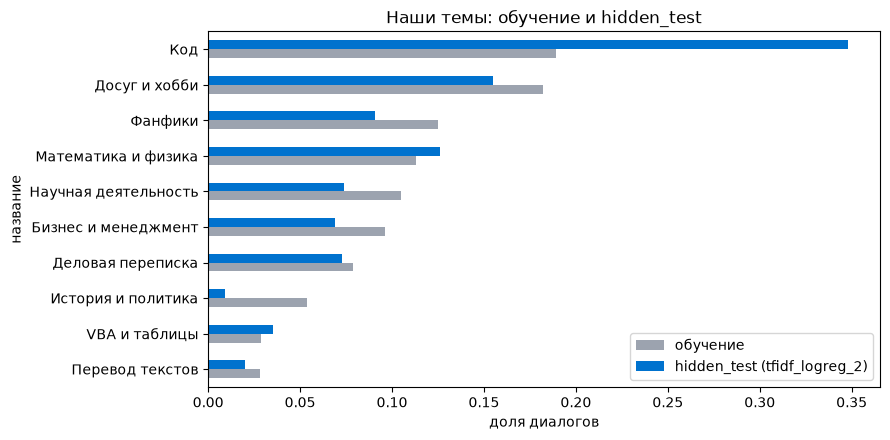

In [12]:
train_share = pd.read_csv(os.path.join(ARTIFACTS_DIR, "topics_table.csv")).set_index("название")["доля"]

counts = pd.DataFrame({name: pd.Series(p).value_counts() for name, p in predictions.items()})
counts = counts.reindex(train_share.index).fillna(0).astype(int)
shares = (counts / counts.sum()).round(3)
shares.insert(0, "доля в обучении", train_share)

print("Число диалогов по темам:")
display(counts)
print("Доли по темам:")
display(shares)

fig, ax = plt.subplots(figsize=(9, 4.5))
plot = pd.DataFrame({"обучение": train_share, f"hidden_test ({MAIN_MODEL})": shares[MAIN_MODEL]})
plot.sort_values("обучение").plot.barh(ax=ax, color=["#9CA3AF", "#0072CE"])
ax.set_xlabel("доля диалогов")
ax.set_title("Наши темы: обучение и hidden_test")
plt.tight_layout()
plt.show()

## 5. Кластеризация hidden_test


In [25]:
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

SEED = su.SEED
N_COMPONENTS = 100

lsa_h = make_pipeline(su.make_tfidf(), TruncatedSVD(N_COMPONENTS, random_state=SEED), Normalizer(copy=False))
X_h = lsa_h.fit_transform(texts_h)

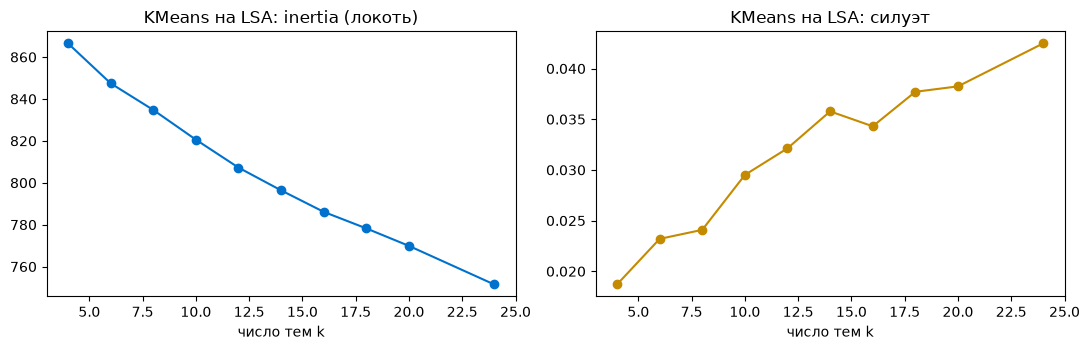

,inertia,silhouette
k,,
4,866.504,0.019
6,847.451,0.023
8,834.751,0.024
10,820.569,0.030
12,807.238,0.032
14,796.379,0.036
16,786.120,0.034
18,778.227,0.038
20,769.879,0.038


In [33]:
K_GRID = [4, 6, 8, 10, 12, 14, 16, 18, 20, 24]

rows = []
for k in K_GRID:
    km = KMeans(k, n_init=5, random_state=SEED).fit(X_h)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_h, km.labels_, random_state=SEED)})
scan_h = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(scan_h.index, scan_h["inertia"], "o-", color="#0072CE");   axes[0].set_title("KMeans на LSA: inertia (локоть)")
axes[1].plot(scan_h.index, scan_h["silhouette"], "o-", color="#C58B00"); axes[1].set_title("KMeans на LSA: силуэт")
for ax in axes:
    ax.set_xlabel("число тем k")
plt.tight_layout()
plt.show()
display(scan_h.round(3))

In [15]:
N_TOPICS = 10   # как в обучении: ровно столько классов знают сохранённые модели

km_h = KMeans(N_TOPICS, n_init=10, random_state=SEED).fit(X_h)
labels_h = km_h.labels_

shares_km = np.bincount(labels_h) / len(labels_h)
print("диалогов по кластерам:", np.bincount(labels_h).tolist())
print(f"силуэт: {silhouette_score(X_h, labels_h, random_state=SEED):.3f} | "
      f"Дэвис — Болдин: {davies_bouldin_score(X_h, labels_h):.3f} | "
      f"min доля: {shares_km.min():.3f} | max доля: {shares_km.max():.3f}")

диалогов по кластерам: [34, 109, 101, 104, 78, 48, 87, 138, 113, 178]
силуэт: 0.030 | Дэвис — Болдин: 4.817 | min доля: 0.034 | max доля: 0.180


## 6. Читаем кластеры и называем их нашими темами

Для каждого кластера печатаем **долю**, **характерные слова** и **типичные диалоги**.

Названия подбираем автоматически, **не используя сохранённые модели**, сравниваем характерные слова кластера со словами тем из `topics_table.csv` и назначаем темы кластерам по одной.

Таблица совпадений ниже нужна, чтобы глазами проверить назначение.


In [26]:
terms_h = su.distinctive_terms(texts_h, labels_h, n_terms=13)     # 13 характерных слов
reps_h = su.representatives(X_h, labels_h, n=5)                   # 5 типичных диалогов
preview_h = su.extract_preview(messages_h).loc[texts_h.index].to_numpy()

for c in range(N_TOPICS):
    print(f"━━ кластер {c} | {np.mean(labels_h == c):.1%} диалогов")
    print("   слова:", ", ".join(terms_h[c]))
    for i in reps_h[c]:
        print("   •", preview_h[i][:170])

━━ кластер 0 | 3.4% диалогов
   слова: translat, english, spanish, verb, latin, russian, chines, languag, european, mean, sentenc, name, anim
   • Which English verb means "遇见" in Chinese, rhymes with "life" and bears certain degree of literary tinge? | No | Which English verb is synonymous with "encounter", rhymes 
   • Translate to English  "Gothic Federati" | How do you say "Gothic Federation" or "Federation of the Goths" in Latin? | Which contemporary language best emulates what we th
   • Translate "yo momma" from English to Polish. | Is "yo momma" more offensive than "twoja mama"? | What about "twoja mamunia"?
   • Translate to English  "原来伊甸园是这个样子" | Can you break it down into morphemes? Write the original Chinese as its own line. Same for the translation bel | Can you rewrite your
   • hello hola | {'role': 'user',  'content': 'translate the following "ち、チョロ過ぎる…突然主人公に惚れるチョロインの如くチョロくになってしまった…！" to English\n  | Please, translate the following ち、チョロ過ぎる…突然主
━━ кластер 1 | 11.0% диа

In [27]:
topics_tbl = pd.read_csv(os.path.join(ARTIFACTS_DIR, "topics_table.csv"))
topic_words = {row["название"]: [w.strip() for w in row["слова"].split(",")] for _, row in topics_tbl.iterrows()}
topic_names = list(topic_words)

# чем выше слово в обоих списках, тем больше вклад: 1/(место в кластере + 1) + 1/(место в теме + 1)
overlap = np.zeros((N_TOPICS, len(topic_names)))
for c in range(N_TOPICS):
    rank_cluster = {w: i for i, w in enumerate(terms_h[c])}
    for j, name in enumerate(topic_names):
        overlap[c, j] = sum(1 / (rank_cluster[w] + 1) + 1 / (r + 1)
                            for r, w in enumerate(topic_words[name]) if w in rank_cluster)

rows_idx, cols_idx = linear_sum_assignment(-overlap)               # максимум суммарного совпадения
auto_name = {int(c): topic_names[j] for c, j in zip(rows_idx, cols_idx)}

TOPIC_OVERRIDE = {}   # например: {3: "Фанфики"} — если автоназвание кластера не устроило

name_of_h = {c: TOPIC_OVERRIDE.get(c, auto_name.get(c, f"тема_{c:02d}: " + ", ".join(terms_h[c][:3])))
             for c in range(N_TOPICS)}
y_h = np.array([name_of_h[c] for c in labels_h], dtype=object)

print("Совпадение характерных слов кластеров (строки) со словами наших тем (столбцы):")
display(pd.DataFrame(overlap, columns=topic_names).round(2).rename_axis("кластер"))

cluster_table = pd.DataFrame({
    "кластер": range(N_TOPICS),
    "название": [name_of_h[c] for c in range(N_TOPICS)],
    "доля": [round(float(np.mean(labels_h == c)), 3) for c in range(N_TOPICS)],
    "слова": [", ".join(terms_h[c][:8]) for c in range(N_TOPICS)],
}).set_index("кластер")
display(cluster_table)

duplicated = pd.Series(list(name_of_h.values())).duplicated().any()
print("Внимание: у каких-то кластеров одинаковые названия (проверьте TOPIC_OVERRIDE)" if duplicated
      else "Названия всех кластеров уникальны")

Совпадение характерных слов кластеров (строки) со словами наших тем (столбцы):


,Код,Досуг и хобби,Фанфики,Математика и физика,Научная деятельность,Бизнес и менеджмент,Деловая переписка,История и политика,VBA и таблицы,Перевод текстов
кластер,,,,,,,,,,
0,0.00,0.58,0.00,0.00,0.00,0.0,0.00,0.0,0.00,4.63
1,0.00,2.00,0.85,0.00,0.00,0.0,0.00,0.0,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,4.7,0.00,0.0,0.00,0.00
3,1.72,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.00,0.00
4,0.00,0.00,0.00,1.78,0.00,0.0,0.00,0.0,0.00,0.00
5,1.51,0.00,0.00,0.75,0.00,0.0,0.00,0.0,5.36,0.00
6,1.34,0.00,0.00,0.24,0.00,0.0,0.00,0.0,0.29,0.00
7,0.00,0.00,0.00,0.00,2.84,0.0,2.08,0.0,0.00,0.31
8,0.00,0.86,3.22,0.00,0.00,0.0,0.00,0.0,0.00,0.21


,название,доля,слова
кластер,,,
0,Перевод текстов,0.034,"translat, english, spanish, verb, latin, russian, chines, languag"
1,Досуг и хобби,0.110,"game, play, day, old, pain, doctor, long, love"
2,Бизнес и менеджмент,0.102,"manag, busi, compani, experi, develop, market, job, industri"
3,История и политика,0.105,"file, command, instal, run, packag, directori, linux, version"
4,Математика и физика,0.079,"equat, atom, energi, water, reaction, point, light, mass"
5,VBA и таблицы,0.048,"column, valu, sheet, cell, row, date, rang, dim"
6,Деловая переписка,0.088,"const, html, color, width, imag, react, button, code"
7,Научная деятельность,0.139,"answer, student, question, topic, research, learn, inform, articl"
8,Фанфики,0.114,"stori, movi, charact, generat, book, peopl, hypothet, prompt"


Названия всех кластеров уникальны


## 7. Метрики моделей 

In [18]:
rows = [{"model": name, **su.supervised_metrics(y_h, pred)} for name, pred in predictions.items()]
hidden_table = pd.DataFrame(rows).set_index("model")
display(hidden_table.sort_values("ARI", ascending=False).round(3))

best_name = hidden_table.drop(index="dummy_most_frequent_2")["ARI"].idxmax()
print("лучшая модель по ARI:", best_name)

,accuracy,macro_F1,ARI,NMI,homogeneity,completeness,V,purity
model,,,,,,,,
tfidf_logreg_2,0.440,0.450,0.294,0.469,0.440,0.503,0.469,0.505
tfidf_nearest_centroid_2,0.449,0.473,0.292,0.469,0.446,0.495,0.469,0.507
own_weighted_knn_2,0.457,0.459,0.277,0.436,0.406,0.469,0.436,0.500
tfidf_naive_bayes_2,0.424,0.326,0.239,0.413,0.359,0.488,0.413,0.454
dummy_most_frequent_2,0.180,0.030,0.000,0.000,0.000,1.000,0.000,0.180


лучшая модель по ARI: tfidf_logreg_2
